In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time
import scipy.integrate as integrate
import scipy.special as special
from scipy.integrate import simps
import matplotlib as mpl
from scipy.integrate import quad
from scipy.interpolate import UnivariateSpline

In [ ]:
mdr = pd.read_csv("redshift_modulodistancia_585.txt" , sep = " ", header=None).to_numpy()

#### O conjunto de dados utilizados é o Union 2.1(2011), uma compilação do do SCP (Supernova Cosmology Project). É um conjunto com 580 dados.

In [ ]:
rshft = np.array(mdr[:,1])
rshft = np.float64(rshft)
md = mdr[:,2]
erromd = mdr[:,3]

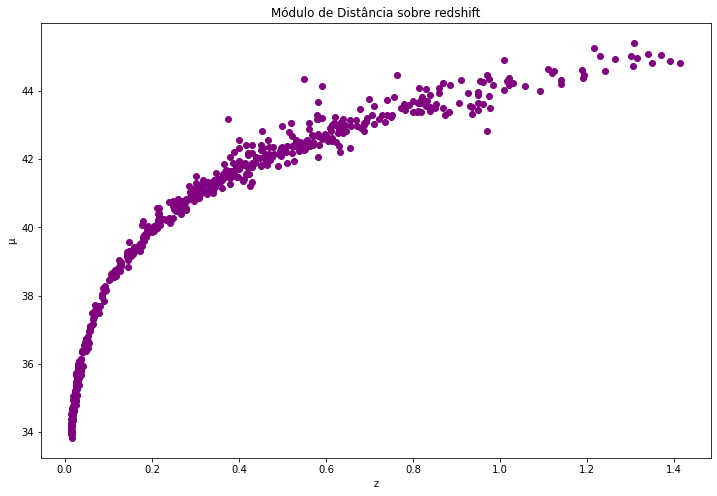

In [ ]:
plt.subplots(figsize=(12,8))
plt.scatter(rshft,md, color='purple')
plt.title('Módulo de Distância sobre redshift')
plt.xlabel('z')
plt.ylabel('μ')
plt.show()

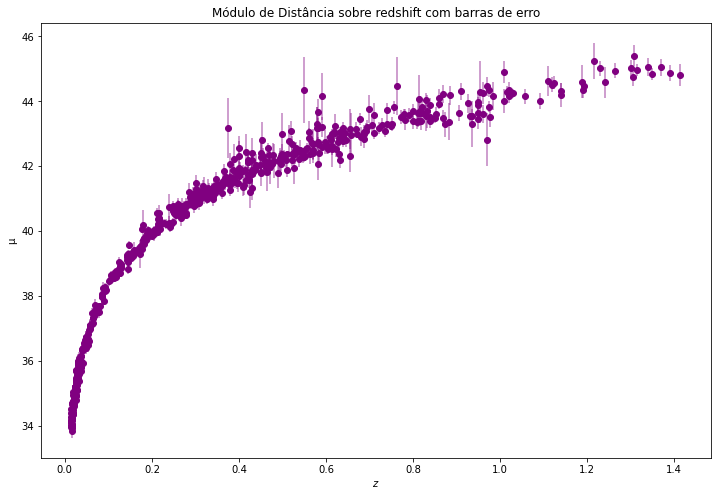

In [ ]:
plt.subplots(figsize=(12,8))
plt.errorbar(rshft,md,yerr=erromd,fmt='.', color='purple', alpha=0.5)
plt.scatter(rshft,md, color='purple')
plt.title('Módulo de Distância sobre redshift com barras de erro')
plt.xlabel('$z$')
plt.ylabel('μ')
plt.show()

O eixo x é o redshift $z$ e o eixo y é o módulo de distância $\mu$ até supernovas do tipo 1a. Note que quanto maior o módulo de distância, maior o redshift.
OBS: foram usados dados de $580$ supernovas do tipo Ia.

Supernovas tipo 1a ocorrem quando uma anã branca começa a absorver massa de sua companheira em um sistema binário.
Em um limite de massa da anã branca bem específico (massa de Chandrasekhar) irá ocorrer a explosão de supernova tipo 1a.
Essas supernovas produzem um pico de luminosidade bastante consistente por causa dessa massa crítica e seu pico de luminosidade permite que essas explosões sejam usadas como velas padrão para medir a distância até galáxias distantes onde elas estão.

o módulo de distância $\mu$ é definido como  $\mu=25+5.log_{10}{dL}  $

e $dL$ é definido como..

$dL=(1+z).(\frac{c}{H0}). \int_{0}^{z} \frac{Ho}{H(z)} \,dz $

Além disso, como

$ H=H0 \sqrt{ \Omega_\Lambda + \Omega_m.(1+z)^{3}}$
    
e temos a "igualdade da soma cósmica" no modelo  $ΛCDM$ que é

$1 = Ω_M + Ω_Λ + Ω_k$

E, no modelo que irei aplicar nesse código $Ω_k=0$ (universo flat) então

$Ω_Λ =1 - Ω_M$

e...

### $dL=(1+z).(\frac{c}{H0}). \int_{0}^{z} \frac{1}{\sqrt{\Omega_m.(1+z)^{3}+1-\Omega_m}} \,dz $

que é o mesmo que $dL=(1+z).Dh. \int_{0}^{z} \frac{1}{\sqrt{\Omega_m.(1+z)^{3}+1-\Omega_m}} \,dz $

como $H_0$ pode ser definido como $100.h$  Km/s/Mpc então...

$dL=(1+z).(\frac{c}{100.h}). \int_{0}^{z} \frac{1}{\sqrt{\Omega_m.(1+z)^{3}+1-\Omega_m}} \,dz $

### Fixando o valor da velocidade da luz no vácuo como $c=299792.458 km/s$ e deixando $h$ e $\Omega_m$ livres, temos que:


### $dL=(1+z).(\frac{2997.92458}{h}). \int_{0}^{z} \frac{1}{\sqrt{\Omega_m.(1+z)^{3}+1-\Omega_m}} \,dz $

In [ ]:
##funcao p calcular a integral
def integrate_spline_approx(f,right_endpts,npts=100):
    x_min = min(0,*right_endpts)
    x_max = max(right_endpts)
    pad = (x_max-x_min)/10
    x_min-=pad
    x_max+=pad
    x_space = np.linspace(x_min,x_max,npts)
    spl = UnivariateSpline(x_space,f(x_space),s=0)

    return np.array([spl.integral(0,right_endpt) for right_endpt in right_endpts])

In [ ]:
def integrando (z,param):
    ohm=param[0]
    result_integrando=1/((ohm*((1+z)**3)+1-ohm)**(1/2))
    return result_integrando

In [ ]:
def dl(z,param):
    ohm=param[0]
    h=param[1]
    result_dl=(1+z)*(2997.92458/h)*integrate_spline_approx(lambda z:integrando(z,param),z)
    return result_dl

In [ ]:
def mu(z,param):
    ohm=param[0]
    h=param[1]
    result_mu=25 + 5*(np.log10(dl(z,param)))
    return result_mu

In [ ]:
def chi2(ohm,h):
    sigma = erromd**2

    return np.sum((mu(rshft,[ohm,h])-md)**2/sigma)

In [ ]:
start = time.time()
chi2_min = 1009
for i in range(1,1001):
    h = i*5/1000
    for j in range(1,1000):
        ohm = j*5/1000
        if  chi2(ohm, h) < chi2_min:
            chi2_min = chi2(ohm, h)
            h_min = h
            ohm_min = ohm
end = time.time()
dur1=end-start
print('o ohm é: ',ohm_min,'o h é: ', h_min,'o H0 é: ',h_min*100,'km/s/Mpc. O chi² mínimo é: ', chi2_min,'o tempo que levou para rodar é: ', dur1,'s')

<ipython-input-162-bb58b15dd4b4>:3: RuntimeWarning: invalid value encountered in sqrt
  result_integrando=1/((ohm*((1+z)**3)+1-ohm)**(1/2))


o ohm é:  0.28 o h é:  0.7 o H0 é:  70.0 km/s/Mpc. O chi² mínimo é:  562.2566664096075 o tempo que levou para rodar é:  1337.0437622070312 s


Então, para o método $GRID$, nos ranges mostrados acima, para os 580 dados de supernovas Ia do Union2.1, temos que:

$\Omega_m=0.28$

$h=0.7$
        
$H_0=70.0 km/s/Mpc$
            

$\chi^2=562.257$

In [ ]:
covsys= pd.read_csv("covcomsys_teste2.txt" , sep = " ", header=None).to_numpy()
lcovsys = covsys[:,0]
covmatrixsys = np.reshape(lcovsys, (580, 580))


def chi_2covsys(ohm, h):
    Σ_inv= np.linalg.inv(covmatrixsys)
    μmatrix=(mu(rshft,[ohm,h])-md)
    μmatrixT = np.transpose(mu(rshft,[ohm,h])-md)
    return (μmatrixT.dot(Σ_inv)).dot(μmatrix)

start = time.time()
chi2_mincovsys = 1009
for i in range(1,1001):
    h = i*5/1000
    for j in range(1,1000):
        ohm = j*5/1000
        if  chi_2covsys(ohm, h) < chi2_mincovsys:
            chi2_mincovsys = chi_2covsys(ohm, h)
            h_min_covsys = h
            ohm_min_covsys = ohm
end = time.time()
dur2=end-start
print('o ohm é: ',ohm_min_covsys,'o h é: ', h_min_covsys,'o H0 é: ',h_min_covsys*100,'km/s/Mpc. O chi² mínimo é: ', chi2_mincovsys,'o tempo que levou para rodar é: ', dur2,'s')

covsemsys= pd.read_csv("covsemsys_teste2.txt" , sep = " ", header=None).to_numpy()
lcovsemsys = covsemsys[:,0]
covsemsys = np.reshape(covsemsys, (580, 580))

#### Vou usar os mesmos dados e as mesmas funções. Mas agora ao invés do grid irei usar o MCMC.

In [ ]:
ohm_old =np.random.rand()
h_old = 0.5+(np.random.rand()*0.5)

In [ ]:
chi2_old = chi2(ohm_old,h_old)

In [ ]:
f1 = open('mychain.txt', "a+")
f1.write( '1'+"   "+str(chi2_old)+"   "+str(ohm_old)+"   "+str(h_old)+ "\n")

65

In [ ]:
weight = 1

In [ ]:
f1 = open('mychain.txt', "a+")

for i in range(1000000):
    hnew = h_old+(-1+2*np.random.rand() )*0.1
    ohmnew = ohm_old+(-1+2*np.random.rand())*0.1

    chi2_new = chi2(ohmnew,hnew)

    alpha = np.exp(-(chi2_new-chi2_old)/2)

    t = np.random.rand()

    if  t<= alpha:

        f1.write( str(weight)+"   "+str(chi2_old)+"   "+str(ohm_old)+"   "+str(h_old)+ "\n")
        h_old = hnew
        ohm_old = ohmnew
        chi2_old = chi2_new
        weight = 1

    else:
        weight = weight+1
        #f1.write( '1'+"   "+str(chi2_old)+"   "+str(H0_old)+"   "+str(omegam_old)+ "\n")


f1.write( str(weight)+"   "+str(chi2_new)+"   "+str(ohmnew)+"   "+str(hnew)+ "\n")

f1.close()
print('cabô')

<ipython-input-301-a1cc225be5fc>:9: RuntimeWarning: overflow encountered in exp
  alpha = np.exp(-(chi2_new-chi2_old)/2)


cabô


In [ ]:
chain = []
with open('mychain.txt') as f:
    for line in f:
        chain.append([(x) for x in line.split()])



In [ ]:
len(chain)

14086

In [ ]:
pesos= np.array([float(chain[i][0]) for i in range(1,len(chain))])
chi2_vec = np.array([float(chain[i][1]) for i in range(1,len(chain))])
ohm_vec = np.array([float(chain[i][2]) for i in range(1,len(chain))])
h_vec = np.array([float(chain[i][3]) for i in range(1,len(chain))])

In [ ]:
chi2min = 100000
for i in range(len(chi2_vec)):
    if chi2_vec[i]<chi2min:
        chi2min = chi2_vec[i]
        res = [chi2min,h_vec[i],ohm_vec[i]]
print(res)

[562.2267136030681, 0.7000217390225182, 0.27774468825730597]


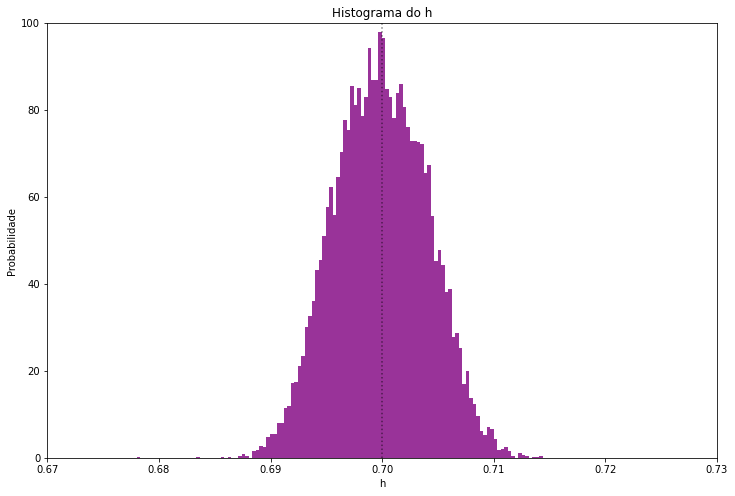

In [ ]:
plt.subplots(figsize=(12,8))
#plt.grid(True, alpha=0.2)
plt.hist(h_vec,1000, density=True, facecolor='purple', alpha=0.8)
plt.xlabel('h')
plt.ylabel('Probabilidade')
plt.title('Histograma do h')
plt.xlim(0.67, 0.73)
plt.ylim(0, 100)
plt.axvline(x=0.7000217390225182, color='black', alpha=0.5, linestyle=':')
plt.show()

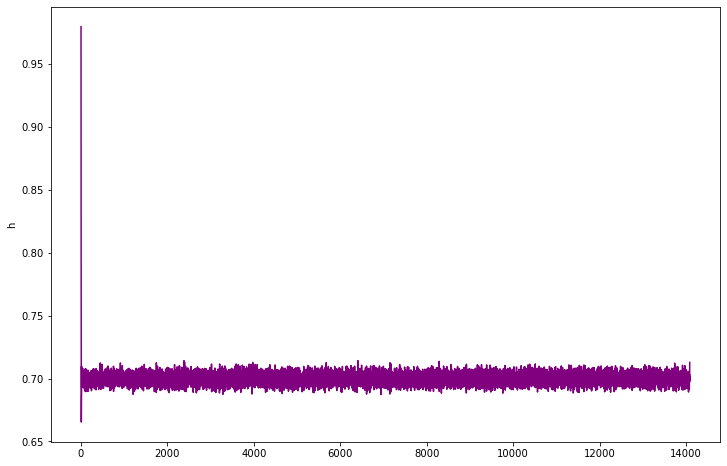

In [ ]:
plt.subplots(figsize=(12,8))
plt.plot(h_vec, color='purple')
plt.ylabel('h')
plt.show()

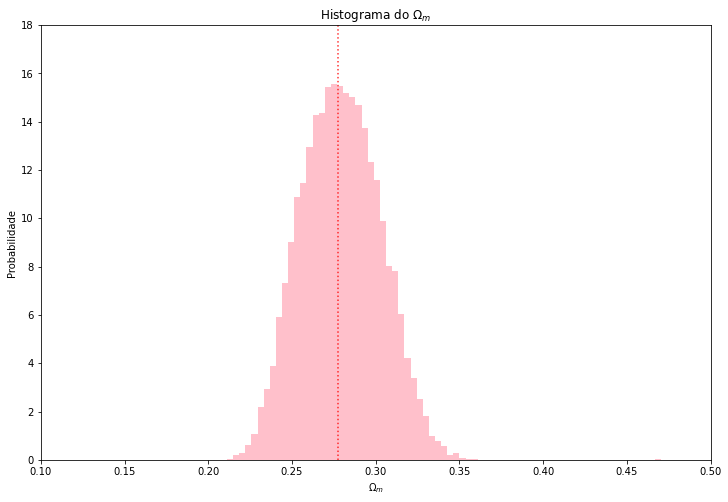

In [ ]:
plt.subplots(figsize=(12,8))
plt.hist(ohm_vec,100, density=True, facecolor='pink')
plt.xlabel('$\Omega_m$')
plt.ylabel('Probabilidade')
plt.title('Histograma do $\Omega_m$')
plt.xlim(0.1, 0.5)
plt.ylim(0, 18)
plt.axvline(x=0.27774468825730597, color='red', alpha=0.8, linestyle=':')

plt.show()

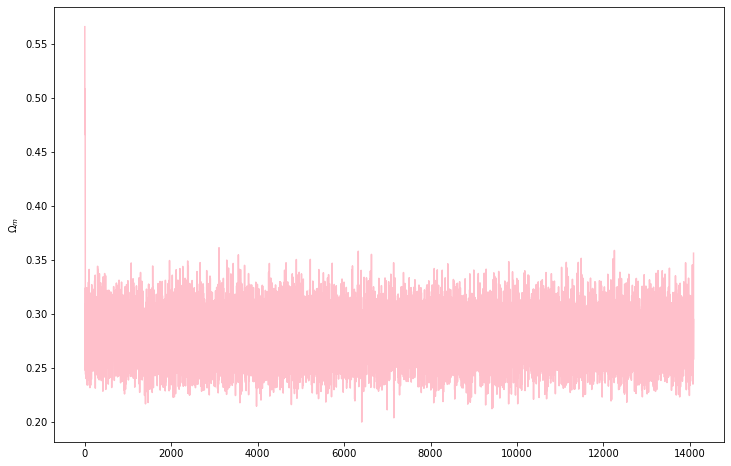

In [ ]:
plt.subplots(figsize=(12,8))
plt.plot(ohm_vec, color='pink')
plt.ylabel('$\Omega_m$')

plt.show()

Com o MCMC, obtivemos nos ranges mostrados anteriormente, para os 580 dados de supernovas Ia do Union2.1 :

$\Omega_m=0.28$

$h=0.70$
        
$H_0=70.0 km/s/Mpc$

$\chi^2 = 562.23$

Que são valores iguais aos obtidos no método GRID. Com diferenças no $\Omega_m$ e no $\chi^2$ nas casas centimais. O que era esperado, afinal usei o mesmo conjunto de dados e as mesmas funções.
A diferença é que o método MCMC se mostrou mais eficiente em termos de TEMPO computacional gasto para fazer o código rodar, podendo trabalhar em um range bem maior que o grid em um tempo similar.
Isso ocorre porque o MCMC não perde muito tempo calculando as regiões em que a probabilidade do $\chi^2$ ser mínima é quase 0.